# S1-01 · 从视频到可执行 affordance（oracle 版）｜SceneFun3D 场景 421069 / 视频 42444490

**这一步回答：** 只用视频、简单深度和设备自带位姿（不重建），能把功能部件放到多准的三维位置上？据此能不能算出"手放在哪、部件怎么动、人站在哪"？

| | 内容 |
|---|---|
| 测试时输入 | hires RGB（1440×1920，10 FPS）、iPad LiDAR 深度或单目深度、ARKit 位姿；**不用**激光扫描、`hires_depth`（由扫描渲染）、`hires_poses`（配准到扫描） |
| 真值用途 | 扫描上的部件和运动轴投影成**训练标签**（Step 3）；评测时用 Faro→ARKit 变换把预测换到扫描坐标系打分；`hires_depth` 只作 oracle 对照 |
| oracle 的含义 | 本 notebook 的部件位置和运动轴来自标签（Step 3），目的是先看清链路和误差来源；S1 第 7 步才换成模型预测 |
| 关键帧 | 按时间均匀取 `N_KEYFRAMES` 帧，不看标签；计算分辨率 720×960（每 2 像素取 1，内参精确缩放） |
| 对应文档 | [讨论稿](../../docs/mem/mem分支_问题定义与讨论稿_2026-11-10.md) 第 12、15 节 |

运行：`conda activate affordance3d`；先下载 `python scripts/download_scenefun3d.py --visit 421069 --video 42444490`，再加 ARKit 资产 `python scripts/download_scenefun3d.py --visit 421069 --video 42444490 --assets lowres_depth lowres_wide_intrinsics confidence lowres_poses transform`（约 230 MB）；单目深度模型首次运行时下载到 Hugging Face 缓存（约 1.5 GB）。在仓库根目录打开本 notebook，Run All；深度预测缓存在 `runs/mem_s1/`。

## Step 0 · 参数

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import open3d as o3d
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display
from scipy.spatial import cKDTree

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
sys.path.insert(0, str(ROOT))

from affordance3d.frames import Frame
from affordance3d.geometry import backproject, project, subsample_frame, transform_points
from affordance3d.mem.actionable import (BODY_RADIUS_M, FOOT_BODY_RADIUS_M, FOOT_STAND_DISTANCE_M, STAND_DISTANCE_M,
                                         distance_to_part, floor_height, is_free, plan_stand, surface_normal)
from affordance3d.mem.depth_models import MonoDepth, depth_errors
from affordance3d.mem.inputs import index_video
from affordance3d.mem.labels import BACKGROUND, part_label_map, projected_axis
from affordance3d.scenefun3d import evenly_spaced, index_sequence, load_frames, read_annotations, read_laser_scan

pio.renderers.default = "plotly_mimetype"
%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "font.size": 9,
                     "font.sans-serif": ["PingFang SC", "Heiti SC", "Arial Unicode MS", "DejaVu Sans"],
                     "axes.unicode_minus": False})

DATA = ROOT / "data" / "scenefun3d"
VISIT, VIDEO = "421069", "42444490"
N_KEYFRAMES = 40
PIXEL_STEP = 2  # 1440x1920 -> 720x960
MONO_MODELS = {
    "DA-V2 S": "depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf",
    "DA-V2 L": "depth-anything/Depth-Anything-V2-Metric-Indoor-Large-hf",
}
# Depth Pro (apple/DepthPro-hf) was tried on 2026-11-10: on the M1 GPU its output was unusable (correlation with the
# true depth -0.21, field of view 39 deg vs the true 49 deg). Left out until it is re-checked on CUDA.
DEPTH_TOL_M = 0.05  # visibility test when projecting labels (as in E0)
ON_PART_M = 0.03  # a contact point within 3 cm of the part counts as "on the part"
NORMAL_WINDOW_PX = 24  # half-size of the depth window for the supporting-surface normal (720x960 pixels)
MIN_PART_PIXELS = 10  # parts seen in fewer pixels get no actionable entry (not enough evidence)
GT_NORMAL_RADIUS_M = 0.10  # scan neighbourhood (without the part itself) for the ground-truth normal
VOXEL_M = 0.05  # occupancy grid for the free-space check
SHOULDER_M, REACH_M, LOW_PART_M = 1.4, 0.75, 0.5
UP = np.array([0.0, 0.0, 1.0])  # gravity-up of the Faro frame (ground truth side)
OUT = ROOT / "runs" / "mem_s1"
OUT.mkdir(parents=True, exist_ok=True)
print(f"data: {DATA.relative_to(ROOT)}   outputs: {OUT.relative_to(ROOT)}")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


data: data/scenefun3d   outputs: runs/mem_s1


## Step 1 · 输入是什么，真值是什么

ARKit 位姿和 LiDAR 深度按横屏存储；需要顺时针转几次才正，**只由 ARKit 位姿推算**（重力方向在图像中的朝向）。hires 帧本身按竖屏正向存储。COLMAP 位姿和渲染深度在后面只用于打分。

In [2]:
vid = index_video(DATA, VISIT, VIDEO)
gt_index = index_sequence(DATA, VISIT, VIDEO)  # COLMAP poses + depth rendered from the scan: ground truth only
times = [t for t in vid.rgb_times if t in gt_index.depth]
keyframes = [times[i] for i in evenly_spaced(len(times), N_KEYFRAMES)]

scan_xyz, scan_rgb = read_laser_scan(DATA / VISIT / f"{VISIT}_laser_scan.ply")
crop = np.load(DATA / VISIT / f"{VISIT}_crop_mask.npy")
elements = read_annotations(DATA / VISIT / f"{VISIT}_annotations.json")
motions = {m["annot_id"]: m for m in json.loads((DATA / VISIT / f"{VISIT}_motions.json").read_text())["motions"]}
descriptions = json.loads((DATA / VISIT / f"{VISIT}_descriptions.json").read_text())["descriptions"]
part_points = [scan_xyz[e.indices] for e in elements]
task_of = {}
for d in descriptions:
    for annot_id in d["annot_id"]:
        task_of.setdefault(annot_id, d["description"])

faro_to_arkit = vid.faro_to_arkit
arkit_to_faro = np.linalg.inv(faro_to_arkit)
# Input-side gravity: ARKit world +z, expressed in the Faro frame in which everything is scored.
UP_INPUT = arkit_to_faro[:3, :3] @ np.array([0.0, 0.0, 1.0])
display(pd.DataFrame([
    ("输入", "hires RGB", f"{len(vid.rgb_times)} 帧，1440×1920，10 FPS"),
    ("输入", "iPad LiDAR 深度 + 置信度", f"{len(vid.lidar_times)} 帧，256×192，60 FPS；只保留高置信度像素"),
    ("输入", "ARKit 位姿", f"{len(vid.arkit_times)} 个；转正需顺时针 {vid.cw_turns} 次（由 ARKit 位姿推算）"),
    ("输入", "单目深度", "从 hires RGB 预测，见下方候选"),
    ("真值", "hires_depth（由扫描渲染）", f"{len(gt_index.depth)} 帧，只作 oracle 与评测"),
    ("真值", "hires_poses（COLMAP，扫描坐标系）", f"{len(gt_index.poses)} 个，只作评测"),
    ("真值", "激光扫描与标注", f"{len(scan_xyz):,} 点；{len(elements)} 个部件，{len(motions)} 条运动"),
    ("真值", "Faro → ARKit 变换", "只用于把预测换到扫描坐标系打分"),
], columns=["用途", "资产", "规模"]))
print(f"关键帧：{len(keyframes)} 帧，从 {len(times)} 个同时具备输入和真值的帧中按时间均匀抽取")

,用途,资产,规模
0,输入,hires RGB,1025 帧，1440×1920，10 FPS
1,输入,iPad LiDAR 深度 + 置信度,7201 帧，256×192，60 FPS；只保留高置信度像素
2,输入,ARKit 位姿,1193 个；转正需顺时针 1 次（由 ARKit 位姿推算）
3,输入,单目深度,从 hires RGB 预测，见下方候选
4,真值,hires_depth（由扫描渲染）,1025 帧，只作 oracle 与评测
5,真值,hires_poses（COLMAP，扫描坐标系）,1025 个，只作评测
6,真值,激光扫描与标注,"8,880,684 点；38 个部件，37 条运动"
7,真值,Faro → ARKit 变换,只用于把预测换到扫描坐标系打分


关键帧：40 帧，从 1025 个同时具备输入和真值的帧中按时间均匀抽取


### 1b · 深度：LiDAR 与单目模型，对照扫描渲染的真值

误差在两类像素上统计：全图，以及**功能部件像素**（Step 3 的标签，只用于评测）。部件只有几厘米大，部件处的误差决定接触点准不准。单目模型用设备已知的焦距（Depth Pro 先估计焦距，这里换成真实焦距）。

候选为 Depth Anything V2 metric indoor 的 Small 和 Large。Depth Pro 也试过，但在 M1 的 GPU 上输出不可信（与真值深度的相关系数为负、估计的视场角 39° 而真实为 49°），排查前不纳入比较。

每个单目模型还有一个"× LiDAR 尺度"版本：单目深度的形状通常不错，但绝对尺度可能偏；用同一帧 LiDAR 深度与预测之比的中位数逐帧缩放。LiDAR 是设备自带的输入，所以这一步不用真值。没有 LiDAR 的数据（如 HD-EPIC）可以改用设备 SLAM 的稀疏点定尺度。

In [3]:
image_hw = (1920, 1440)
gt_frames = load_frames(gt_index, keyframes, cw_turns=0, pixel_step=PIXEL_STEP)
label_maps = [part_label_map(part_points, f, DEPTH_TOL_M) for f in gt_frames]  # Step 3 labels, evaluation only
gt_depths = [f.depth_m for f in gt_frames]
lidar_depths = [vid.lidar_depth(t, image_hw)[::PIXEL_STEP, ::PIXEL_STEP] for t in keyframes]


def mono_depths(name: str, model_id: str) -> tuple[list[np.ndarray], float]:
    folder = OUT / "mono" / name.replace(" ", "_")
    folder.mkdir(parents=True, exist_ok=True)
    timing = folder / "seconds_per_frame.json"
    paths = [folder / f"{t}.npy" for t in keyframes]
    if not all(p.exists() for p in paths) or not timing.exists():
        model, seconds = MonoDepth(model_id), []
        for t, path in zip(keyframes, paths):
            rgb = plt.imread(vid.rgb_path(t))
            start = time.perf_counter()
            depth = model.predict(rgb, focal_px=float(vid.intrinsics(t)[0, 0]))
            seconds.append(time.perf_counter() - start)
            np.save(path, depth[::PIXEL_STEP, ::PIXEL_STEP].astype(np.float16))
        timing.write_text(json.dumps(float(np.median(seconds[1:]))))  # first frame includes warm-up
        del model
    return [np.load(p).astype(np.float32) for p in paths], json.loads(timing.read_text())


def lidar_scaled(depths: list[np.ndarray]) -> list[np.ndarray]:
    # Per-frame scale from the device's own LiDAR (an input): median of LiDAR / predicted depth.
    scaled = []
    for depth, lidar in zip(depths, lidar_depths):
        both = (lidar > 0) & (depth > 0)
        scaled.append(depth * np.median(lidar[both] / depth[both]))
    return scaled


sources = {"LiDAR": (lidar_depths, float("nan"))}
for name, model_id in MONO_MODELS.items():
    depths, seconds = mono_depths(name, model_id)
    sources[name] = (depths, seconds)
    sources[f"{name} × LiDAR 尺度"] = (lidar_scaled(depths), seconds)

rows = []
for name, (depths, seconds) in sources.items():
    every = [depth_errors(d, g) for d, g in zip(depths, gt_depths)]
    parts = [depth_errors(d, g, mask=labels >= 0) for d, g, labels in zip(depths, gt_depths, label_maps)]
    rows.append({"深度来源": name,
                 "全图 AbsRel": np.median([e["abs_rel"] for e in every]),
                 "全图中位误差 cm": 100 * np.median([e["median_abs_m"] for e in every]),
                 "全图 δ<1.25": np.median([e["delta1"] for e in every]),
                 "部件处中位误差 cm": 100 * np.nanmedian([e["median_abs_m"] for e in parts]),
                 "覆盖率（有深度的像素）": np.mean([np.mean(d > 0) for d in depths]),
                 "秒/帧（M1 MPS）": seconds})
depth_table = pd.DataFrame(rows).set_index("深度来源")
display(depth_table.style.format({"全图 AbsRel": "{:.3f}", "全图中位误差 cm": "{:.1f}", "全图 δ<1.25": "{:.2f}",
                                  "部件处中位误差 cm": "{:.1f}", "覆盖率（有深度的像素）": "{:.0%}",
                                  "秒/帧（M1 MPS）": "{:.2f}"}, na_rep="设备自带"))
MONO = depth_table.drop(index="LiDAR")["全图 AbsRel"].idxmin()
print(f"后续使用的单目深度：{MONO}（在这个开发场景上按全图 AbsRel 选出，换场景要重新核对）")

,全图 AbsRel,全图中位误差 cm,全图 δ<1.25,部件处中位误差 cm,覆盖率（有深度的像素）,秒/帧（M1 MPS）
深度来源,,,,,,
LiDAR,0.032,2.4,0.99,5.2,88%,设备自带
DA-V2 S,0.348,49.2,0.15,55.5,100%,0.21
DA-V2 S × LiDAR 尺度,0.071,5.3,0.94,13.0,100%,0.21
DA-V2 L,0.353,49.9,0.17,56.1,100%,1.53
DA-V2 L × LiDAR 尺度,0.057,4.7,0.94,11.2,100%,1.53


后续使用的单目深度：DA-V2 L × LiDAR 尺度（在这个开发场景上按全图 AbsRel 选出，换场景要重新核对）


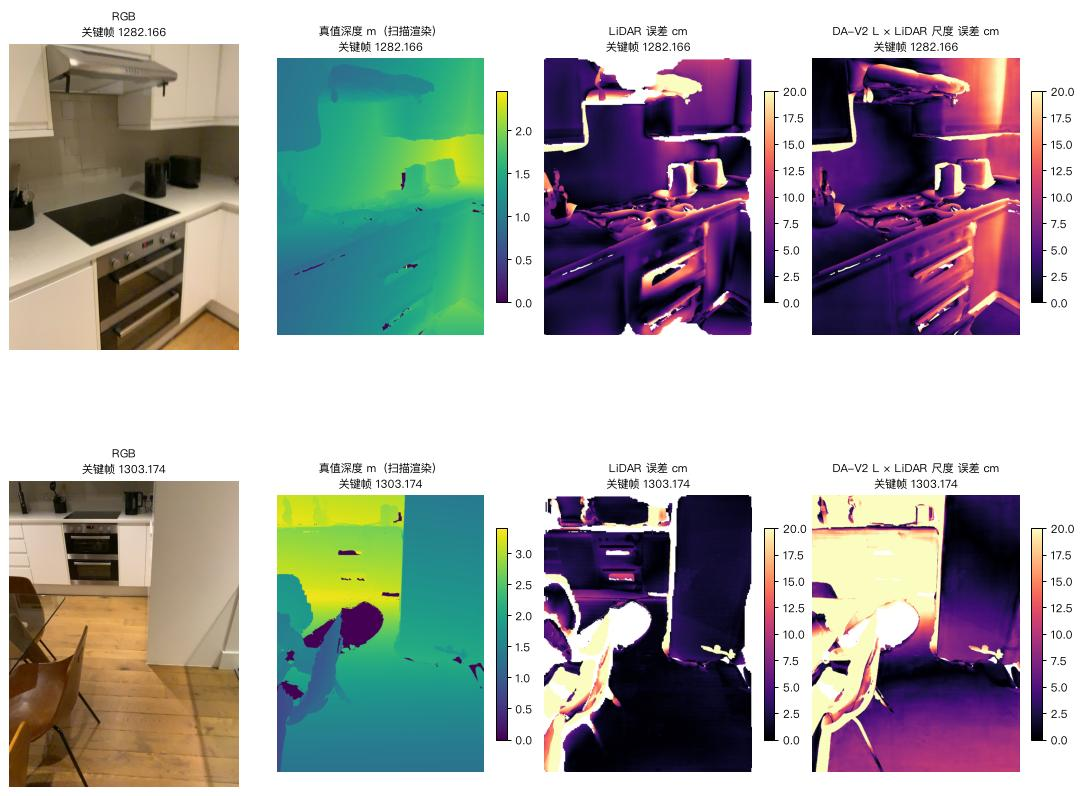

In [4]:
shown = sorted(range(len(keyframes)), key=lambda i: -(label_maps[i] >= 0).sum())[:2]
fig, axes = plt.subplots(len(shown), 4, figsize=(12, 5.2 * len(shown)))
for row, i in enumerate(shown):
    gt = gt_depths[i]
    panels = [(gt_frames[i].rgb, "RGB", None), (gt, "真值深度 m（扫描渲染）", "viridis")]
    for name in ("LiDAR", MONO):
        d = sources[name][0][i]
        err = np.where((gt > 0) & (d > 0), np.abs(d - gt) * 100, np.nan)
        panels.append((err, f"{name} 误差 cm", "magma"))
    for axis, (image, title, cmap) in zip(axes[row], panels):
        shown_image = axis.imshow(image, cmap=cmap, vmin=0 if cmap == "magma" else None,
                                  vmax=20 if cmap == "magma" else None)
        if cmap:
            plt.colorbar(shown_image, ax=axis, fraction=0.046)
        axis.set_title(f"{title}\n关键帧 {keyframes[i]}", fontsize=9)
        axis.axis("off")
plt.tight_layout()
plt.show()

## Step 2 · 轻量三维：不重建，只用逐帧深度和 ARKit 位姿

先看 ARKit 位姿本身离 COLMAP 真值多远，再把"深度误差"和"位姿误差"拆开：每个关键帧的深度点分别用 ARKit 位姿和 COLMAP 位姿放到扫描坐标系，量到激光扫描的距离。

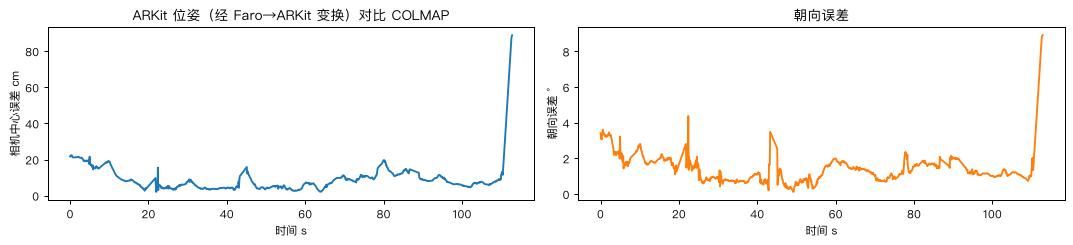

相机中心误差 cm：中位 7.2，p90 15.8，最大 88.9；朝向误差 °：中位 1.23，最大 8.91


In [5]:
pose_rows = []
for t in times:
    arkit = arkit_to_faro @ vid.arkit_pose(t)
    colmap = gt_index.poses[gt_index.matched[t][0]]
    relative = colmap[:3, :3].T @ arkit[:3, :3]
    pose_rows.append((float(t) - float(times[0]), 100 * np.linalg.norm(arkit[:3, 3] - colmap[:3, 3]),
                      np.degrees(np.arccos(np.clip((np.trace(relative) - 1) / 2, -1, 1)))))
pose_err = pd.DataFrame(pose_rows, columns=["t", "centre_cm", "rotation_deg"])
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
axes[0].plot(pose_err.t, pose_err.centre_cm)
axes[0].set(xlabel="时间 s", ylabel="相机中心误差 cm", title="ARKit 位姿（经 Faro→ARKit 变换）对比 COLMAP")
axes[1].plot(pose_err.t, pose_err.rotation_deg, color="tab:orange")
axes[1].set(xlabel="时间 s", ylabel="朝向误差 °", title="朝向误差")
plt.tight_layout()
plt.show()
print("相机中心误差 cm：中位 {:.1f}，p90 {:.1f}，最大 {:.1f}；朝向误差 °：中位 {:.2f}，最大 {:.2f}".format(
    pose_err.centre_cm.median(), pose_err.centre_cm.quantile(0.9), pose_err.centre_cm.max(),
    pose_err.rotation_deg.median(), pose_err.rotation_deg.max()))

In [6]:
scan_cloud = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(scan_xyz[crop]))
scan_cm = np.asarray(scan_cloud.voxel_down_sample(0.01).points)
scan_tree = cKDTree(scan_cm)


def input_frame(i: int, depth: np.ndarray, gt_pose: bool = False) -> Frame:
    pose = gt_frames[i].cam_to_world if gt_pose else arkit_to_faro @ vid.arkit_pose(keyframes[i])
    return Frame(i, gt_frames[i].rgb, depth, gt_frames[i].intrinsics, pose)  # pose in the Faro frame


decomposition = []
for name in ("LiDAR", MONO, "真值深度"):
    depths = gt_depths if name == "真值深度" else sources[name][0]
    for pose_name, gt_pose in (("ARKit 位姿", False), ("COLMAP 位姿（真值）", True)):
        distances = np.concatenate([scan_tree.query(backproject(input_frame(i, d, gt_pose), stride=8)[0])[0]
                                    for i, d in enumerate(depths)])
        decomposition.append({"深度": name, "位姿": pose_name, "到扫描中位距离 cm": 100 * np.median(distances),
                              "p90 cm": 100 * np.quantile(distances, 0.9)})
decomposition = pd.DataFrame(decomposition).pivot(index="深度", columns="位姿").round(1)
display(decomposition.loc[["LiDAR", MONO, "真值深度"]])

到扫描中位距离 cm                 p90 cm              
位姿                   ARKit 位姿 COLMAP 位姿（真值） ARKit 位姿 COLMAP 位姿（真值）
深度                                                                
LiDAR                     3.3           1.7      6.6           7.1
DA-V2 L × LiDAR 尺度        3.9           3.2     12.2          12.2
真值深度                      3.7           0.4      9.3           0.8

In [7]:
rng = np.random.default_rng(0)
shown_scan = scan_cm[rng.choice(len(scan_cm), 40000, replace=False)]
points, distances = [], []
for i, d in enumerate(sources[MONO][0]):
    p, _ = backproject(input_frame(i, d), stride=20)
    points.append(p)
    distances.append(scan_tree.query(p)[0])
points, distances = np.concatenate(points), np.concatenate(distances)
arkit_path = np.array([(arkit_to_faro @ vid.arkit_pose(t))[:3, 3] for t in times])
colmap_path = np.array([gt_index.poses[gt_index.matched[t][0]][:3, 3] for t in times])
fig = go.Figure([
    go.Scatter3d(x=shown_scan[:, 0], y=shown_scan[:, 1], z=shown_scan[:, 2], mode="markers",
                 marker=dict(size=1, color="lightgrey"), name="激光扫描（真值）"),
    go.Scatter3d(x=points[:, 0], y=points[:, 1], z=points[:, 2], mode="markers", name=f"{MONO} + ARKit 位姿",
                 marker=dict(size=1.5, color=np.minimum(distances * 100, 20), colorscale="Turbo", cmin=0, cmax=20,
                             colorbar=dict(title="到扫描 cm", len=0.6))),
    go.Scatter3d(x=arkit_path[:, 0], y=arkit_path[:, 1], z=arkit_path[:, 2], mode="lines",
                 line=dict(color="orange", width=4), name="ARKit 相机路径"),
    go.Scatter3d(x=colmap_path[:, 0], y=colmap_path[:, 1], z=colmap_path[:, 2], mode="lines",
                 line=dict(color="royalblue", width=4), name="COLMAP 相机路径（真值）"),
])
fig.update_layout(height=620, margin=dict(l=0, r=0, t=30, b=0), legend=dict(x=0, y=1),
                  scene=dict(aspectmode="data", xaxis_visible=False, yaxis_visible=False, zaxis_visible=False),
                  title=f"不重建的三维：{len(keyframes)} 个关键帧的单目深度点，颜色为到激光扫描的距离")
fig.show()

## Step 3 · 训练标签：把扫描上的部件和运动轴投到关键帧

标签用真值相机（COLMAP 位姿 + 渲染深度）生成，做遮挡检查，和 E0 相同。颜色表示 SceneFun3D 的 9 类动作；箭头是运动轴（转动部件为转轴，平移部件为推拉方向）。这些标签之后用来训练 affordance、动作类型和运动方向三个预测头。

In [8]:
ACTIONS = ["rotate", "key_press", "tip_push", "hook_pull", "pinch_pull", "hook_turn", "foot_push", "plug_in", "unplug"]
colour_of = dict(zip(ACTIONS, plt.get_cmap("tab10").colors))
seen_pixels = np.array([[(labels == p).sum() for labels in label_maps] for p in range(len(elements))])
visibility = pd.DataFrame({"动作": [e.label for e in elements], "可见关键帧数": (seen_pixels > 0).sum(axis=1),
                           "最多像素": seen_pixels.max(axis=1)})
summary = visibility.groupby("动作").agg(部件数=("动作", "size"), 至少一帧可见=("可见关键帧数", lambda s: int((s > 0).sum())),
                                         两帧以上可见=("可见关键帧数", lambda s: int((s > 1).sum())),
                                         最多像素中位数=("最多像素", "median"))
display(summary)
print(f"{(visibility['可见关键帧数'] > 0).sum()}/{len(elements)} 个部件至少在一个关键帧中可见；"
      f"可见部件在最佳关键帧中的像素数中位为 {visibility.loc[visibility['最多像素'] > 0, '最多像素'].median():.0f}（720×960）")

,部件数,至少一帧可见,两帧以上可见,最多像素中位数
动作,,,,
foot_push,1,1,1,1009.0
hook_pull,4,3,2,358.5
hook_turn,5,4,4,87.0
key_press,2,2,2,342.0
pinch_pull,2,2,1,4.5
plug_in,7,6,3,43.0
rotate,11,11,7,57.0
tip_push,5,4,1,23.0
unplug,1,0,0,0.0


33/38 个部件至少在一个关键帧中可见；可见部件在最佳关键帧中的像素数中位为 57（720×960）


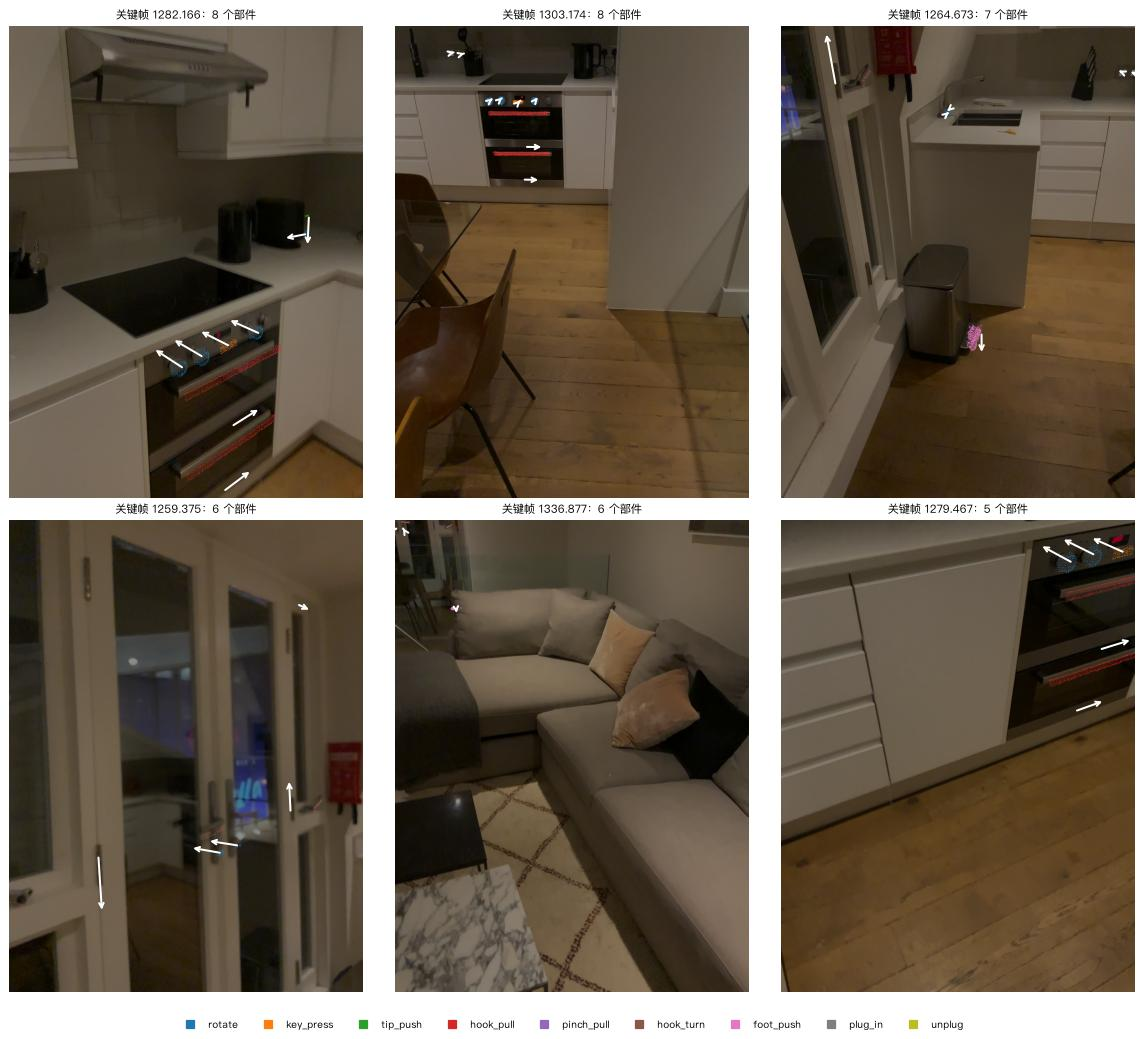

In [9]:
best_frames = sorted(range(len(keyframes)), key=lambda i: -len(set(np.unique(label_maps[i])) - {BACKGROUND}))[:6]
fig, axes = plt.subplots(2, 3, figsize=(13, 11.5))
for axis, i in zip(axes.flat, best_frames):
    frame, labels = gt_frames[i], label_maps[i]
    overlay = (frame.rgb * 0.55).astype(np.uint8)
    for p in set(np.unique(labels)) - {BACKGROUND}:
        overlay[labels == p] = (np.array(colour_of[elements[p].label]) * 255).astype(np.uint8)
    axis.imshow(overlay)
    for p in set(np.unique(labels)) - {BACKGROUND}:
        m = motions.get(elements[p].annot_id)
        if m is None:
            continue
        start, end = projected_axis(scan_xyz[m["motion_origin_idx"]], np.array(m["motion_dir"]), frame, 0.15)
        axis.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", color="white", lw=1.6))
    axis.set_title(f"关键帧 {keyframes[i]}：{len(set(np.unique(labels)) - {BACKGROUND})} 个部件", fontsize=9)
    axis.axis("off")
handles = [plt.Line2D([], [], marker="s", ls="", color=colour_of[a], label=a) for a in ACTIONS]
fig.legend(handles=handles, loc="lower center", ncol=9, fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## Step 4 · 可执行 affordance（oracle 标签 + 输入深度和位姿）

对每个在某个关键帧中至少有 `MIN_PART_PIXELS` 个像素的部件，选像素最多的关键帧，计算一组能直接驱动人形的量：

| 量 | 怎么算（只用输入） |
|---|---|
| 接触点 | 标签中心像素，按输入深度提升到三维（部件像素深度的中位数） |
| 法向 | 接触点周围（去掉部件本身）的输入深度拟合平面，即部件所在的门板、墙面或台面，朝向相机 |
| 运动轴 | 本步仍是 oracle（SceneFun3D 运动标注），第 7 步换成预测 |
| 地面 | 所有关键帧输入点的高度中最常见的低值（ARKit 世界 +z 为重力向上） |
| 站立点 | 沿法向的水平分量后退 0.5 m（踩踏板为 0.45 m，身体圆柱半径取 0.15 m）落到地面；身体圆柱（半径 0.2 m）内有输入点就先再后退（最多 0.45 m，例如隔着台面够墙上的插座），再转 ±30°/±60° |
| 够得到 | 肩高 1.4 m 到接触点不超过 0.75 m；接触点离地低于 0.5 m 记为"需要下蹲" |

评测在扫描坐标系进行：接触点到真值部件点的距离（≤3 cm 算落在部件上）、法向与扫描法向的夹角、站立点在**激光扫描**里是否真的空闲。三种深度各算一遍，并且分别用 ARKit 和 COLMAP 位姿，把位姿误差单独看出来。

In [10]:
def voxels(points: np.ndarray) -> np.ndarray:
    cloud = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points))
    return np.asarray(cloud.voxel_down_sample(VOXEL_M).points)


scan_occupied = voxels(scan_xyz[crop])
gt_floor = floor_height(scan_cm[:, 2])
visible_parts = [p for p in range(len(elements)) if seen_pixels[p].max() >= MIN_PART_PIXELS]
full_tree = cKDTree(scan_xyz[crop])
crop_index = np.flatnonzero(crop)


def gt_normal(p: int, viewer: np.ndarray) -> np.ndarray:
    # Normal of the supporting surface around the part (scan points nearby, the part itself removed).
    near = crop_index[full_tree.query_ball_point(part_points[p].mean(axis=0), GT_NORMAL_RADIUS_M)]
    near = np.setdiff1d(near, elements[p].indices)
    return surface_normal(scan_xyz[near], viewer)


def actionable_for(depths: list[np.ndarray], gt_pose: bool) -> pd.DataFrame:
    frames = [input_frame(i, d, gt_pose) for i, d in enumerate(depths)]
    observed = np.concatenate([backproject(f, stride=8)[0] for f in frames])
    floor, occupied = floor_height(observed @ UP_INPUT), voxels(observed)
    rows = []
    for p in visible_parts:
        i = int(np.argmax(seen_pixels[p]))
        frame, rows_cols = frames[i], np.argwhere(label_maps[i] == p)
        centre = np.median(rows_cols, axis=0)
        v, u = rows_cols[np.argmin(np.linalg.norm(rows_cols - centre, axis=1))]
        part_depth = frame.depth_m[rows_cols[:, 0], rows_cols[:, 1]]
        part_depth = part_depth[part_depth > 0]
        row = {"part": p, "动作": elements[p].label, "任务": task_of.get(elements[p].annot_id, ""),
               "关键帧": keyframes[i], "像素": len(rows_cols), "uv": (int(u), int(v))}
        if not len(part_depth):
            rows.append({**row, "有深度": False})
            continue
        ray = np.linalg.inv(frame.intrinsics) @ np.array([u, v, 1.0])
        contact = transform_points(frame.cam_to_world, (ray * np.median(part_depth))[None])[0]
        top, left = max(v - NORMAL_WINDOW_PX, 0), max(u - NORMAL_WINDOW_PX, 0)
        window = frame.depth_m[top:v + NORMAL_WINDOW_PX, left:u + NORMAL_WINDOW_PX]
        off_part = label_maps[i][top:v + NORMAL_WINDOW_PX, left:u + NORMAL_WINDOW_PX] != p
        ys, xs = np.nonzero((window > 0) & off_part)  # supporting surface around the part
        pixels = np.stack([xs + left, ys + top], axis=1)
        rays = np.linalg.inv(frame.intrinsics) @ np.vstack([pixels.T, np.ones(len(pixels))])
        neighbourhood = transform_points(frame.cam_to_world, (rays * window[ys, xs]).T)
        viewer = frame.cam_to_world[:3, 3]
        normal = surface_normal(neighbourhood, viewer)
        foot = elements[p].label == "foot_push"
        stand = plan_stand(contact, normal, UP_INPUT, floor, viewer, occupied, max_points=2,
                           distance=FOOT_STAND_DISTANCE_M if foot else STAND_DISTANCE_M,
                           radius=FOOT_BODY_RADIUS_M if foot else BODY_RADIUS_M)
        shoulder = stand.position + SHOULDER_M * UP_INPUT
        rows.append({**row, "有深度": True, "contact": contact, "normal": normal, "stand": stand.position,
                     "facing": stand.facing, "moved": stand.moved, "free_input": stand.free,
                     "接触点误差 cm": 100 * distance_to_part(contact, part_points[p]),
                     "法向误差 °": np.degrees(np.arccos(np.clip(normal @ gt_normal(p, viewer), -1, 1))),
                     "free_gt": is_free(stand.position, scan_occupied, UP, max_points=2),
                     "离地 m": contact @ UP_INPUT - floor, "肩到接触点 m": np.linalg.norm(shoulder - contact),
                     "站立点离真实地面 cm": 100 * (stand.position[2] - gt_floor)})
    table = pd.DataFrame(rows)
    table.attrs["floor"] = floor  # input-side floor height along UP_INPUT
    return table


results = {(name, pose): actionable_for(gt_depths if name == "真值深度" else sources[name][0], pose == "COLMAP")
           for name in ("LiDAR", MONO, "真值深度") for pose in ("ARKit", "COLMAP")}
summary_rows = []
for (name, pose), table in results.items():
    ok = table[table["有深度"]]
    summary_rows.append({"深度": name, "位姿": pose, "部件": len(table), "有深度": len(ok),
                         "接触点中位误差 cm": ok["接触点误差 cm"].median(),
                         f"落在部件上（≤{100 * ON_PART_M:.0f} cm）": (ok["接触点误差 cm"] <= 100 * ON_PART_M).mean(),
                         "法向中位误差 °": ok["法向误差 °"].median(),
                         "站立点在扫描中空闲": ok["free_gt"].mean(), "需要换位置": ok["moved"].mean(),
                         "站立点离真实地面 cm": ok["站立点离真实地面 cm"].median()})
actionable_summary = pd.DataFrame(summary_rows).set_index(["深度", "位姿"])
display(actionable_summary.style.format({"接触点中位误差 cm": "{:.1f}", f"落在部件上（≤{100 * ON_PART_M:.0f} cm）": "{:.0%}",
                                          "法向中位误差 °": "{:.0f}", "站立点在扫描中空闲": "{:.0%}",
                                          "需要换位置": "{:.0%}", "站立点离真实地面 cm": "{:+.1f}"}))

In [11]:
main = results[(MONO, "ARKit")]
per_part = main[main["有深度"]].assign(
    **{"LiDAR 误差 cm": results[("LiDAR", "ARKit")].set_index("part").loc[main[main["有深度"]].part, "接触点误差 cm"].values,
       "真值深度 误差 cm": results[("真值深度", "ARKit")].set_index("part").loc[main[main["有深度"]].part, "接触点误差 cm"].values,
       f"{MONO}+COLMAP 误差 cm": results[(MONO, "COLMAP")].set_index("part").loc[main[main["有深度"]].part, "接触点误差 cm"].values,
       "够得到": lambda d: np.where(d["离地 m"] < LOW_PART_M, "需要下蹲", np.where(d["肩到接触点 m"] <= REACH_M, "是", "太远"))})
columns = ["动作", "任务", "像素", "接触点误差 cm", "LiDAR 误差 cm", "真值深度 误差 cm", f"{MONO}+COLMAP 误差 cm",
           "法向误差 °", "free_gt", "moved", "够得到"]
display(per_part[columns].rename(columns={"接触点误差 cm": f"{MONO} 误差 cm", "free_gt": "扫描中空闲", "moved": "换过位置"})
        .sort_values("动作").style.format(precision=1).hide(axis="index"))

动作,任务,像素,DA-V2 L × LiDAR 尺度 误差 cm,LiDAR 误差 cm,真值深度 误差 cm,DA-V2 L × LiDAR 尺度+COLMAP 误差 cm,法向误差 °,扫描中空闲,换过位置,够得到
foot_push,Open the trash can located in the kitchen near the sink,1009,0.3,0.5,0.6,0.8,4.6,True,False,需要下蹲
hook_pull,Open the glass door next to the black floor lamp,55,6.5,nan,2.5,0.1,7.6,True,False,是
hook_pull,Open the bottom oven door,662,9.0,6.0,3.8,13.8,5.5,True,True,需要下蹲
hook_pull,Open the top oven door,832,7.3,10.6,3.9,11.6,15.4,True,True,太远
hook_turn,Open the window located above the trash can in the kitchen,82,3.4,5.7,2.6,3.8,40.3,True,True,太远
hook_turn,Open the small window located near to the portable air conditioner,173,4.5,1.9,1.8,3.5,35.3,True,True,太远
hook_turn,Open the left balcony door located in the kitchen,151,12.0,1.0,4.8,16.8,29.4,True,False,是
hook_turn,Open the right balcony door located in the kitchen,87,14.5,nan,6.9,19.0,28.2,True,False,是
key_press,Turn on the TV using the remote control located on the TV stand,516,5.4,5.5,5.5,4.4,28.8,False,False,需要下蹲
key_press,,168,3.8,2.8,4.2,6.6,8.6,True,True,太远


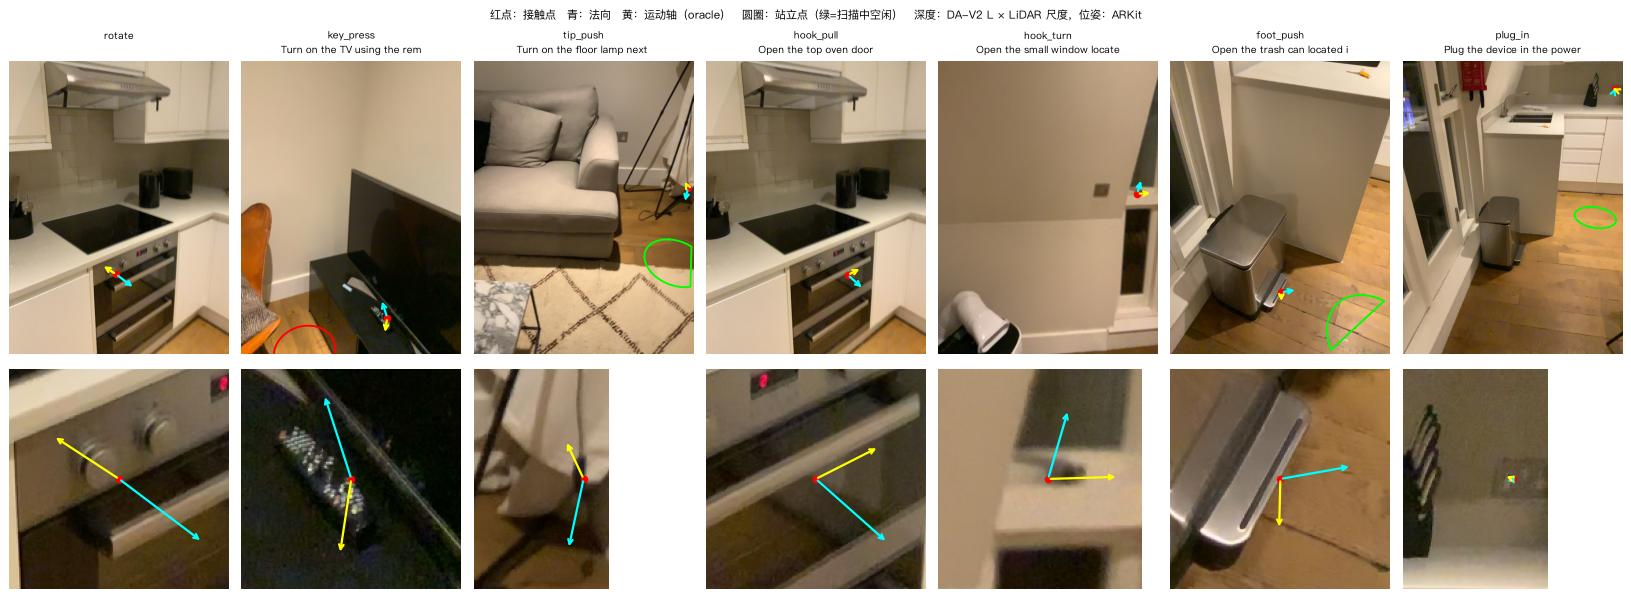

In [12]:
def footprint(frame: Frame, centre: np.ndarray, radius: float = 0.2) -> np.ndarray:
    angles = np.linspace(0, 2 * np.pi, 40)
    circle = centre + radius * np.stack([np.cos(angles), np.sin(angles), np.zeros_like(angles)], axis=1)
    uv, _, inside = project(circle, frame)
    return uv if inside.all() else uv[inside]


examples = []
for action in ACTIONS:  # one example per action type, the part seen with most pixels
    rows = main[(main["动作"] == action) & main["有深度"]].sort_values("像素", ascending=False)
    if len(rows):
        examples.append(rows.iloc[0])
examples = examples[:8]
fig, axes = plt.subplots(2, len(examples), figsize=(2.6 * len(examples), 7.2))
for column, row in enumerate(examples):
    i = keyframes.index(row["关键帧"])
    frame = input_frame(i, sources[MONO][0][i])
    m = motions.get(elements[row.part].annot_id)
    for r, zoom in enumerate((False, True)):
        axis = axes[r, column]
        axis.imshow(frame.rgb)
        u, v = row["uv"]
        start, normal_end = projected_axis(row["contact"], row["normal"], frame, 0.12)
        axis.annotate("", xy=normal_end, xytext=start, arrowprops=dict(arrowstyle="->", color="cyan", lw=1.8))
        if m is not None:
            _, motion_end = projected_axis(row["contact"], np.array(m["motion_dir"]), frame, 0.12)
            axis.annotate("", xy=motion_end, xytext=start, arrowprops=dict(arrowstyle="->", color="yellow", lw=1.8))
        axis.plot(u, v, "o", color="red", ms=5)
        ring = footprint(frame, row["stand"])
        if len(ring):
            axis.plot(ring[:, 0], ring[:, 1], color="lime" if row["free_gt"] else "red", lw=1.5)
        if zoom:
            axis.set_xlim(u - 80, u + 80)
            axis.set_ylim(v + 80, v - 80)
        axis.axis("off")
    axes[0, column].set_title(f"{row['动作']}\n{row['任务'][:28]}", fontsize=8)
fig.suptitle(f"红点：接触点　青：法向　黄：运动轴（oracle）　圆圈：站立点（绿=扫描中空闲）　深度：{MONO}，位姿：ARKit", fontsize=9)
plt.tight_layout()
plt.show()

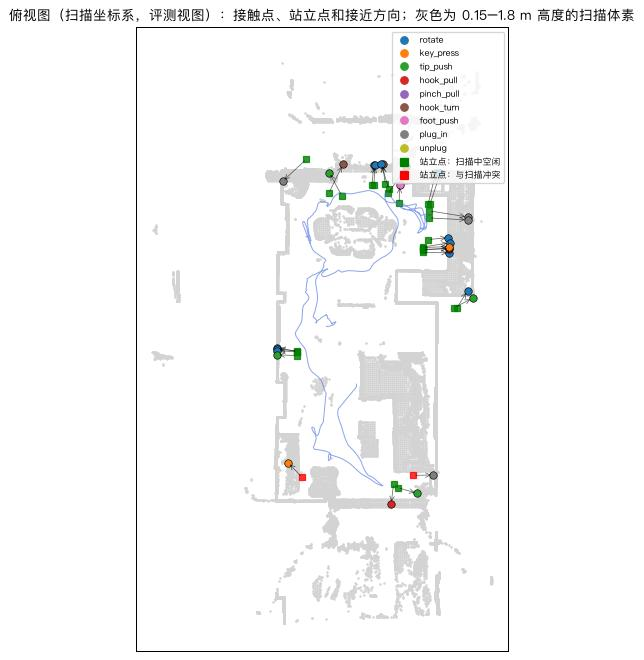

In [13]:
band = scan_occupied[(scan_occupied[:, 2] > gt_floor + 0.15) & (scan_occupied[:, 2] < gt_floor + 1.8)]
fig, axis = plt.subplots(figsize=(9, 9))
axis.scatter(band[:, 0], band[:, 1], s=1, c="lightgrey")
ok = main[main["有深度"]]
for _, row in ok.iterrows():
    colour = colour_of[row["动作"]]
    axis.plot(*row["contact"][:2], "o", color=colour, ms=6, mec="black", mew=0.5)
    axis.plot(*row["stand"][:2], "s", color="green" if row["free_gt"] else "red", ms=5, alpha=0.8)
    axis.annotate("", xy=row["contact"][:2], xytext=row["stand"][:2],
                  arrowprops=dict(arrowstyle="->", color="black", lw=0.6, alpha=0.6))
axis.plot(colmap_path[:, 0], colmap_path[:, 1], color="royalblue", lw=0.8, alpha=0.6)
handles = [plt.Line2D([], [], marker="o", ls="", color=colour_of[a], label=a) for a in ACTIONS]
handles += [plt.Line2D([], [], marker="s", ls="", color=c, label=l) for c, l in (("green", "站立点：扫描中空闲"), ("red", "站立点：与扫描冲突"))]
axis.legend(handles=handles, fontsize=7, loc="upper right")
axis.set_aspect("equal")
axis.set_title(f"俯视图（扫描坐标系，评测视图）：接触点、站立点和接近方向；灰色为 0.15–1.8 m 高度的扫描体素")
axis.set_xticks([])
axis.set_yticks([])
plt.show()

In [14]:
def as_list(value):
    return np.asarray(value, dtype=float).round(4).tolist()


def motion_fields(annot_id: str) -> dict:
    m = motions.get(annot_id)
    if m is None:
        return {"motion_type": None}
    return {"motion_type": m["motion_type"], "motion_dir_faro": as_list(m["motion_dir"]),
            "motion_origin_faro": as_list(scan_xyz[m["motion_origin_idx"]])}


records = [{"annot_id": elements[r.part].annot_id, "action": r["动作"], "task": r["任务"], "keyframe": r["关键帧"],
            "pixel": list(r["uv"]), "pixels": int(r["像素"]), "contact_faro": as_list(r["contact"]), "normal_faro": as_list(r["normal"]),
            "stand_faro": as_list(r["stand"]), "facing_faro": as_list(r["facing"]), "stand_free_in_scan": bool(r["free_gt"]),
            "stand_moved": bool(r["moved"]), "contact_error_cm": round(float(r["接触点误差 cm"]), 2),
            **motion_fields(elements[r.part].annot_id)}
           for _, r in main[main["有深度"]].iterrows()]
# The chosen input depth and the input cameras of every keyframe, for S1-02 (humanoid display).
inputs_dir = OUT / "inputs"
inputs_dir.mkdir(exist_ok=True)
for i, t in enumerate(keyframes):
    frame = input_frame(i, sources[MONO][0][i])
    np.savez_compressed(inputs_dir / f"{t}.npz", depth=frame.depth_m.astype(np.float16), intrinsics=frame.intrinsics,
                        cam_to_world=frame.cam_to_world)
manifest = {"visit": VISIT, "video": VIDEO, "keyframes": keyframes, "pixel_step": PIXEL_STEP, "mono_model": MONO,
            "mono_model_id": MONO_MODELS[MONO.split(" × ")[0]], "lidar_scaled": " × " in MONO, "depth_table": depth_table.reset_index().to_dict("records"),
            "pose_error": {"centre_cm_median": float(pose_err.centre_cm.median()),
                           "rotation_deg_median": float(pose_err.rotation_deg.median())},
            "actionable_summary": actionable_summary.reset_index().to_dict("records"),
            "floor_input": float(results[(MONO, "ARKit")].attrs["floor"]), "up_input": as_list(UP_INPUT),
            "gt_floor": float(gt_floor),
            "note": "oracle labels and motion axes; poses expressed in the Faro frame for evaluation only"}
(OUT / "actionable_oracle.json").write_text(json.dumps(records, indent=1, ensure_ascii=False))
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=1, ensure_ascii=False, default=float))
print("saved:", *(str((OUT / n).relative_to(ROOT)) for n in ("actionable_oracle.json", "manifest.json")), sep="\n  ")

saved:
  runs/mem_s1/actionable_oracle.json
  runs/mem_s1/manifest.json


### 读结果的方式

- **Step 1b**：部件处的深度误差比全图更重要；单目模型的选择只在这个开发场景上做过。
- **Step 2**：同一种深度换成 COLMAP 位姿后误差下降的部分，就是 ARKit 位姿的代价；换成真值深度后下降的部分，是深度的代价。
- **Step 4**：oracle 版的误差全部来自输入深度和位姿，因此是第 7 步（模型预测）的上限。站立点在扫描中空闲的比例说明只用输入点做的空闲检查是否可信。
- 这里的数字只针对一个场景、一个视频，用来看链路和误差来源，不是方法结论。

### 本次运行记录（2026-11-10，40 个关键帧，720×960）

以下数字只针对这次执行；改动参数后应重新核对。

- **输入约定：** LiDAR 和 ARKit 相机需顺时针转 1 次才正，这只由 ARKit 位姿推算；转正后直接放大即可对上 hires 像素（中位相对误差 1.3%）。
- **深度：**
  - LiDAR 全图中位误差 2.4 cm，部件处 5.2 cm，覆盖 88% 的像素。
  - Depth Anything V2 的绝对尺度偏远约 33%，中位误差约 50 cm；逐帧乘 LiDAR 尺度后，Large 降到 4.7 cm，但部件处仍有 11.2 cm。
  - Depth Pro 在 M1 GPU 上的输出不可信，未纳入比较。
- **位姿：** ARKit 相机中心相对 COLMAP 的误差中位 7.2 cm，p90 15.8 cm，个别帧达 89 cm；朝向中位 1.2°。
- **深度 × 位姿分解（到扫描的中位距离）：**
  - 真值深度 + COLMAP 0.4 cm，换成 ARKit 位姿后 3.7 cm；
  - LiDAR + ARKit 3.3 cm，比"真值深度 + ARKit"还好，因为 LiDAR 和 ARKit 位姿来自同一台设备，彼此一致。
- **标签：** 38 个部件中 33 个至少在一个关键帧中可见；最佳关键帧里的像素数中位为 57。两个 pinch_pull 只有 2–5 个像素，没有生成条目。
- **可执行 affordance（29 个部件）：**
  - 接触点中位误差：LiDAR + ARKit 2.8 cm（54% 落在部件上）；单目 × LiDAR 尺度 + ARKit 7.7 cm（14%）；真值深度 + COLMAP 0.4 cm（97%）。
  - 最后一项说明链路本身正确，误差来自输入深度和 ARKit 位姿。
  - 支撑面法向的中位误差为 13–24°。
  - 站立点在扫描中真正空闲的比例为 75–97%。
- **对第 7 步的提示：**
  - 单目深度在小部件处的误差（约 11 cm）是主要瓶颈。
  - 只用输入点做空闲检查时，没观察到的空间被当成了空闲，违反"未知不等于空闲"，后续需要改。

**下一步：** [S1-02](S1_02_humanoid_approach.ipynb) 按 `runs/mem_s1/actionable_oracle.json` 在关键帧上贴人形（站立 + 伸手 + 运动箭头），并在扫描里检查。